# Student Depression Detection

L'objectif de ce TP est de développer un modèle de Machine Learning capable de prédire la présence de dépression chez les étudiants à partir de caractéristiques générales relatives à leur profil et à leur situation personnelle, académique et sociale.

Le problème est formulé comme une tâche de classification binaire :

- 1 : l'étudiant présente une dépression.

- 0 : l'étudiant ne présente pas de dépression.

### Libs

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import os

import kagglehub
from kagglehub import KaggleDatasetAdapter

### Data importation

In [2]:
path = kagglehub.dataset_download("mkhoirulmustaqim/student-depression-detection-dataset")

file_path = os.path.join(path, "Student Depression Detection Dataset","Student_Depression_Dataset.csv")

df = pd.read_csv(file_path)

print(f"First 5 records:\n{df.head()}")

100%|██████████| 282k/282k [00:00<00:00, 1.23MB/s]

Extracting files...


First 5 records:
   Gender  Age Family_background Relationship_status Marital_status  \
0  Female   22      Middle class              Single      Unmarried   
1    Male   19      Middle class              Single      Unmarried   
2    Male   23      Middle class              Single      Unmarried   
3    Male   20      Middle class         Complicated      Unmarried   
4  Female   21      Middle class              Single      Unmarried   

  Living_style  Current_semester  CGPA friend_circle Health_condition  \
0     Bachelor                 8  3.43           Yes         Critical   
1     Bachelor                 2  3.70           Yes         Abnormal   
2       Family                 8  3.28            No         Abnormal   
3       Family                 2  3.77            No             Good   
4       Family                 1  4.00            No         Abnormal   

   Cost_without_study Home_division Depression  
0               10113    Chittagong        Yes  
1               138

### More data information

In [3]:
print(f"Shape: {df.shape}\nAll columns: {df.columns}\nDatatype of each column:\n{df.dtypes}")

Shape: (4464, 13)
All columns: Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='object')
Datatype of each column:
Gender                  object
Age                      int64
Family_background       object
Relationship_status     object
Marital_status          object
Living_style            object
Current_semester         int64
CGPA                   float64
friend_circle           object
Health_condition        object
Cost_without_study       int64
Home_division           object
Depression              object
dtype: object


### Checking if there is any null value

In [4]:
df.isnull().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

### Checking if there is any duplicated values

In [5]:
df.duplicated().sum()

np.int64(0)

### Dataset resume

In [6]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


## EDA

In [7]:
def show_fig():
    plt.tight_layout()
    plt.show()

### Depression distribution by gender

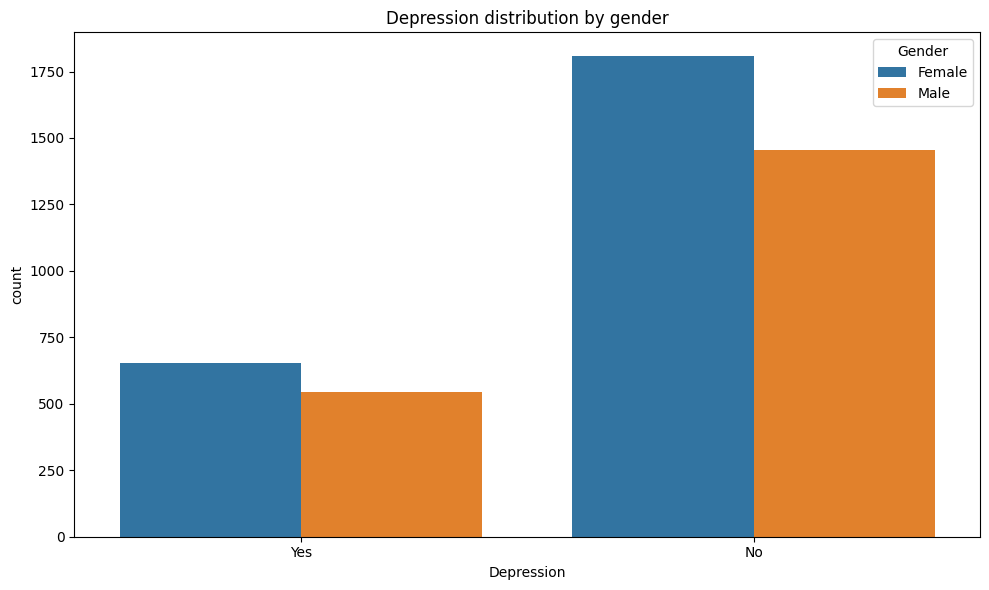

In [8]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Depression', hue='Gender')
plt.title('Depression distribution by gender')
show_fig()

### CGPA boxplot distribution by genders

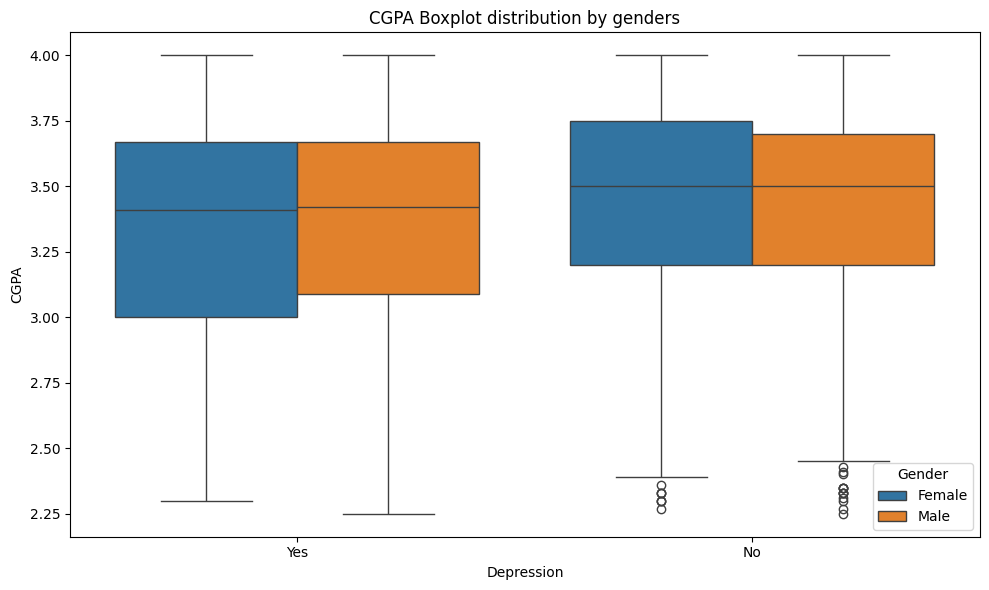

In [9]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Depression', y='CGPA', hue='Gender')
plt.title('CGPA Boxplot distribution by genders')
show_fig()


### Depression distribution by semesters

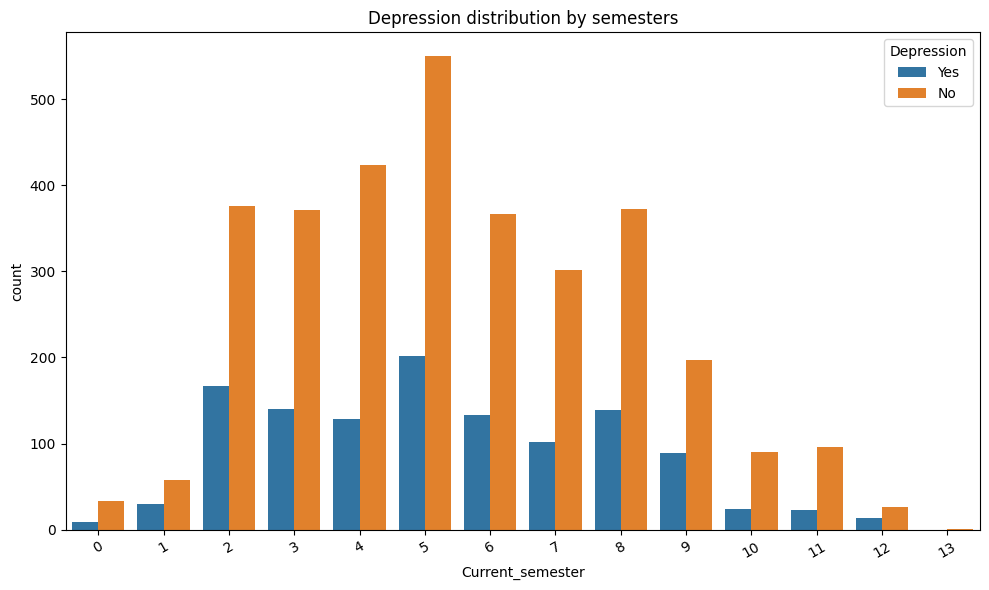

In [10]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Current_semester', hue='Depression')
plt.title('Depression distribution by semesters')
plt.xticks(rotation=30)
show_fig()

### Health condition distribution by gender

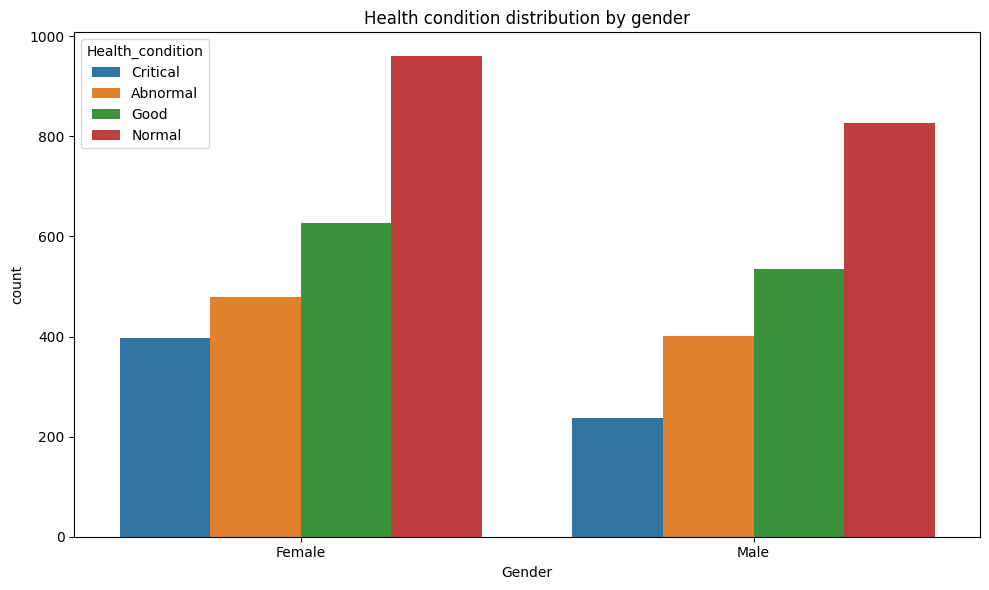

In [11]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Gender', hue='Health_condition')
plt.title('Health condition distribution by gender')
show_fig()

### Depression distribution by health condition

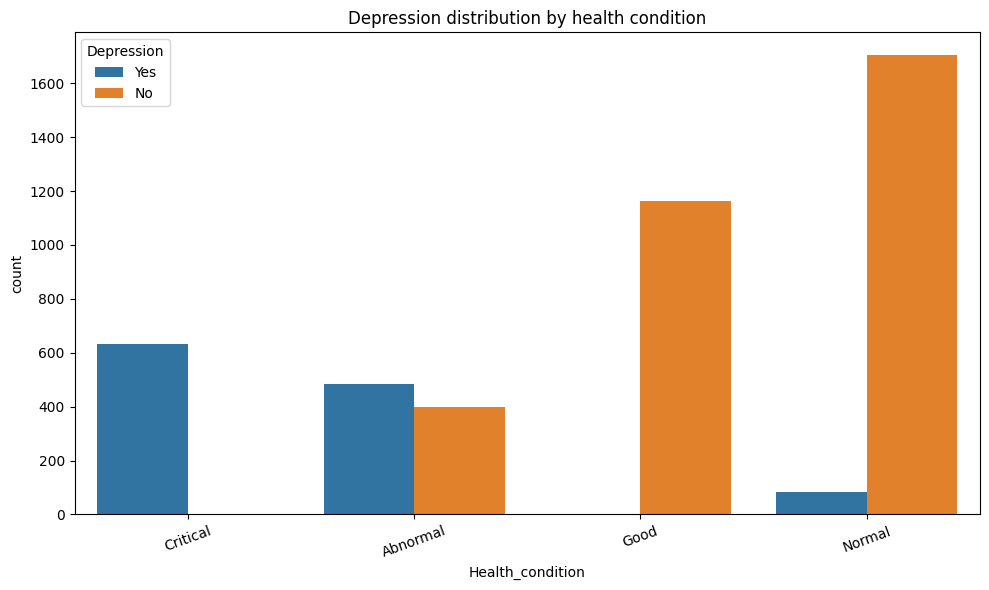

In [12]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Health_condition', hue='Depression')
plt.title('Depression distribution by health condition')
plt.xticks(rotation=20)
show_fig()

## Data transformation

### Data separation

In [13]:
data = df.dropna(subset=['Depression']).copy()
X = data.drop(columns=['Depression'])
y = data['Depression'].astype(str).str.strip()

### Separating numerical and categorical columns

In [14]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

### Building the preprocessing pipeline for each data type

In [15]:
num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer([('num', num_pipe, num_cols), ('cat', cat_pipe, cat_cols)])

model = Pipeline([('preprocessor', preprocessor), ('classifier', LogisticRegression(max_iter=2000))])

### Model training

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Model prediction

In [17]:
y_pred = model.predict(X_test)

### Model evaluation

In [18]:
print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 0.9709

Classification Report:

              precision    recall  f1-score   support

          No       0.97      0.99      0.98       653
         Yes       0.96      0.93      0.94       240

    accuracy                           0.97       893
   macro avg       0.97      0.96      0.96       893
weighted avg       0.97      0.97      0.97       893



### Confunsion matrix

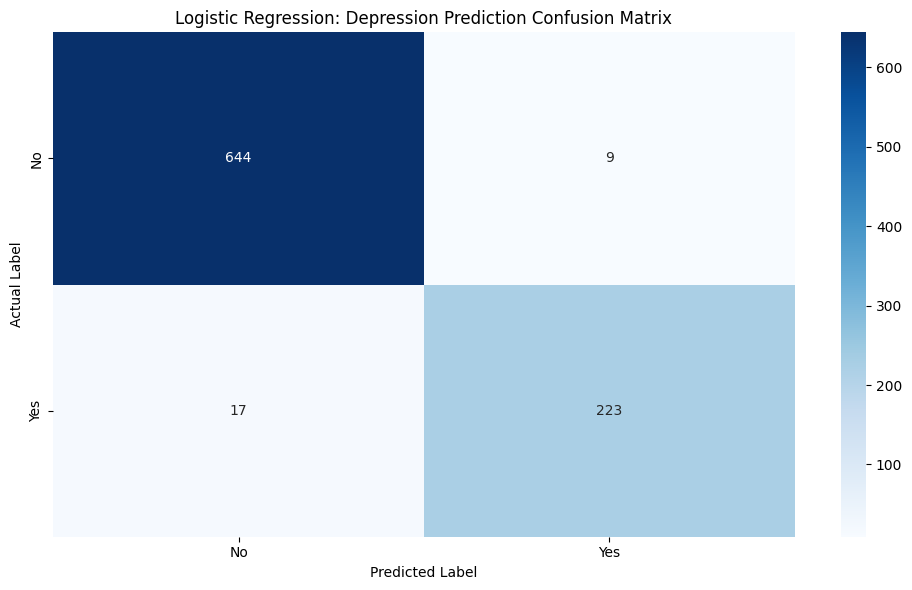

In [19]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
fig = plt.figure(figsize=(10, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.title('Logistic Regression: Depression Prediction Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()